# Phase 6 — Robust Hawkes Market Making via Uncertainty Quantification

Interactive walkthrough of the uncertainty-aware market maker. We treat the Hawkes
parameters `θ = (μ, α, β)` as a random variable with estimation covariance `Σ_θ`,
propagate that uncertainty into the intensity `λ(t)` and into the quotes, and
measure the consequences. **This phase is not about improving PnL** — it is about
quantifying model uncertainty and making the market maker statistically robust.

Sizes here are kept small so the notebook runs in a couple of minutes; the full
study is `python -m analysis.robust_market_making` and its report is
`reports/robust_market_making.md`.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline

from robust.data import load_streams
from robust.covariance import fisher_covariance, PARAM_NAMES
from robust.bootstrap import run_parametric_bootstrap
from robust.delta_method import confidence_band, lambda_bar, lambda_bar_variance
from robust.uncertainty import SidedBeliefs
from robust.robust_quotes import RobustHawkesASPolicy
from robust.hpc import run_hpc
from market_maker import ASParameters

streams = load_streams()
s_all = streams['all']
print('all stream: n =', s_all.n_events, ' T =', round(s_all.T, 1))
print('theta_hat  =', np.round(s_all.theta, 4))

all stream: n = 24861  T = 23399.6
theta_hat  = [  0.5679 210.5831 452.3497]


## Part 1 — Parameter covariance: observed Fisher information vs bootstrap

`Σ_θ ≈ H⁻¹` (inverse Hessian of the negative log-likelihood, computed in rescaled
coordinates) compared with a parametric bootstrap (simulate from `θ̂`, refit).

In [2]:
fc = fisher_covariance(s_all.theta, s_all.t, s_all.T)
boot = run_parametric_bootstrap(s_all.theta, s_all.T, n_boot=200, n_starts=2, n_jobs=-1)

tbl = pd.DataFrame({
    'estimate': s_all.theta,
    'fisher_SE': fc.std_errors,
    'bootstrap_SE': np.sqrt(np.diag(boot.cov)),
    'bootstrap_bias': boot.bias,
}, index=list(PARAM_NAMES))
print('Fisher scaled cond =', round(fc.extra['cond_number_scaled'], 1),
      ' min eig =', f"{fc.extra['min_eigenvalue_scaled']:.3g}")
print('\nFisher correlation matrix:\n', np.round(fc.correlation, 3))
tbl

Fisher scaled cond = 13.3  min eig = 1.67e+03

Fisher correlation matrix:
 [[1.    0.145 0.182]
 [0.145 1.    0.858]
 [0.182 0.858 1.   ]]


,estimate,fisher_SE,bootstrap_SE,bootstrap_bias
mu,0.567867,0.005063,0.004368,0.000328
alpha,210.583069,3.855157,2.876006,0.238179
beta,452.349735,7.945258,4.954440,0.491662


## Part 2 — Delta method: confidence band for `λ(t)`

`Var(λ) = ∇fᵀ Σ_θ ∇f` with the analytic gradient `∇f = (1, S_β, −α Q_β)`.

lambda_bar = 1.0625 +/- 0.0247  (95%)


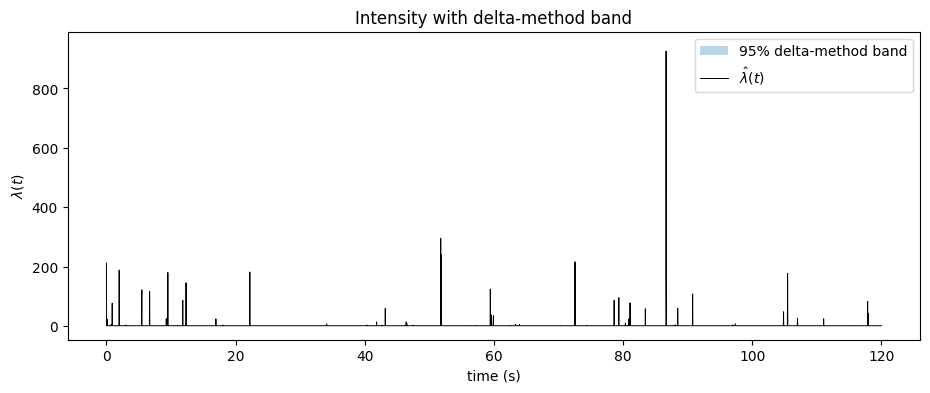

In [3]:
grid = np.linspace(0, 120, 4000)
ev = s_all.t[s_all.t <= 120]
band = confidence_band(grid, ev, s_all.theta, fc.cov, level=0.95)
lb = lambda_bar(s_all.theta); lb_se = np.sqrt(lambda_bar_variance(s_all.theta, fc.cov))
print(f'lambda_bar = {lb:.4f} +/- {1.96*lb_se:.4f}  (95%)')

fig, ax = plt.subplots(figsize=(11, 4))
ax.fill_between(grid, band.lower, band.upper, alpha=0.3, label='95% delta-method band')
ax.plot(grid, band.intensity, 'k', lw=0.7, label=r'$\hat\lambda(t)$')
ax.set(xlabel='time (s)', ylabel=r'$\lambda(t)$', title='Intensity with delta-method band')
ax.legend(); plt.show()

## Part 3 & 5 — Robust backtest: Classical vs Hawkes vs Robust

Per-side beliefs are built from the per-side Fisher covariances; the three
strategies run on identical synthetic flow (common random numbers).

In [4]:
from analysis.robust_backtest import StrategySpec, run_paired_paths

cov_buy = fisher_covariance(streams['buy'].theta, streams['buy'].t, streams['buy'].T).cov
cov_sell = fisher_covariance(streams['sell'].theta, streams['sell'].t, streams['sell'].T).cov
thb, ths = streams['buy'].theta, streams['sell'].theta
beliefs = SidedBeliefs.from_covariances(thb, cov_buy, ths, cov_sell)
params = ASParameters(gamma=0.1, sigma=0.03477, kappa=23.96, A=1.445, T=600.0, q_max=50)

specs = [StrategySpec('Classical', 'poisson'),
         StrategySpec('Hawkes', 'hawkes'),
         StrategySpec('Robust', 'robust', c=1.0)]
df = run_paired_paths(thb, ths, beliefs, cov_buy, cov_sell, params, specs,
                      n_paths=60, impact=0.002, T=600.0, n_jobs=-1)

keys = ['total_pnl', 'sharpe', 'inv_var', 'max_drawdown', 'avg_spread', 'fill_rate']
pd.DataFrame({n: {k: df[f'{k}_{n}'].mean() for k in keys} for n in ['Classical','Hawkes','Robust']})

,Classical,Hawkes,Robust
total_pnl,6.485763,5.818668,4.413233
sharpe,5.048506,5.142022,4.419203
inv_var,2.061657,1.377364,1.120790
max_drawdown,0.758444,0.598193,0.590928
avg_spread,0.119213,0.145074,0.247535
fill_rate,0.285349,0.218251,0.176900


## Part 6 — Statistical significance (paired) with Cohen's d

In [5]:
from analysis.statistics import paired_comparison
for m in ['total_pnl', 'inv_var', 'max_drawdown']:
    r = paired_comparison(df[f'{m}_Hawkes'].to_numpy(), df[f'{m}_Robust'].to_numpy())
    print(f'{m:14s} Robust-Hawkes: mean={r.mean_diff:+.4f} t_p={r.t_p:.2g} '
          f"d={r.cohens_d:+.2f} sig={r.significant}")

total_pnl      Robust-Hawkes: mean=-1.4054 t_p=1e-22 d=-2.02 sig=True
inv_var        Robust-Hawkes: mean=-0.2566 t_p=2.2e-09 d=-0.91 sig=True
max_drawdown   Robust-Hawkes: mean=-0.0073 t_p=0.77 d=-0.04 sig=False


## Part 4 & 7 — Variance-penalised spread vs robustness weight `c`

Response of the robust strategy as `c` grows: spread widens, inventory variance
falls, gross PnL declines (the risk/return trade).

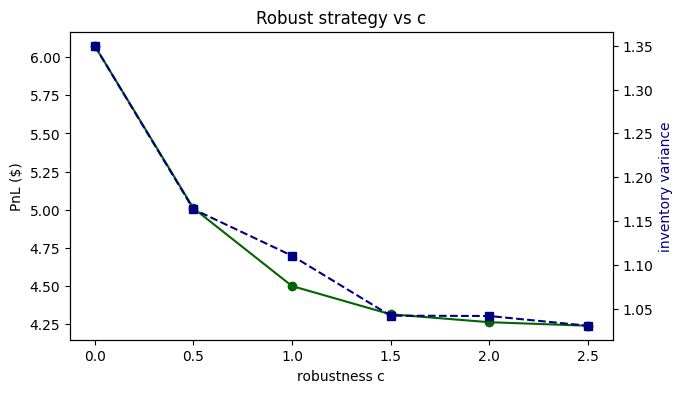

,c,total_pnl,inv_var,sharpe
0,0.0,6.075630,1.349962,5.405279
1,0.5,5.009536,1.163464,4.886711
2,1.0,4.498222,1.110341,4.537308
3,1.5,4.312766,1.041890,4.492527
4,2.0,4.260799,1.041524,4.471835
5,2.5,4.237668,1.030422,4.482108


In [6]:
from analysis.robust_sensitivity import response_curve
curve = response_curve(np.linspace(0, 2.5, 6), thb, ths, cov_buy, cov_sell,
                       n_paths=40, base=params, impact=0.002, T=600.0, n_jobs=-1)
fig, ax = plt.subplots(figsize=(7,4))
ax.plot(curve['c'], curve['total_pnl'], 'o-', color='darkgreen', label='PnL')
ax2 = ax.twinx(); ax2.plot(curve['c'], curve['inv_var'], 's--', color='navy', label='inv var')
ax.set(xlabel='robustness c', ylabel='PnL ($)'); ax2.set_ylabel('inventory variance', color='navy')
plt.title('Robust strategy vs c'); plt.show()
curve

## Part 8 — HPC predictive distributions under `θ ~ N(θ̂, Σ_θ)`

sims: 500  rejected draws: 0


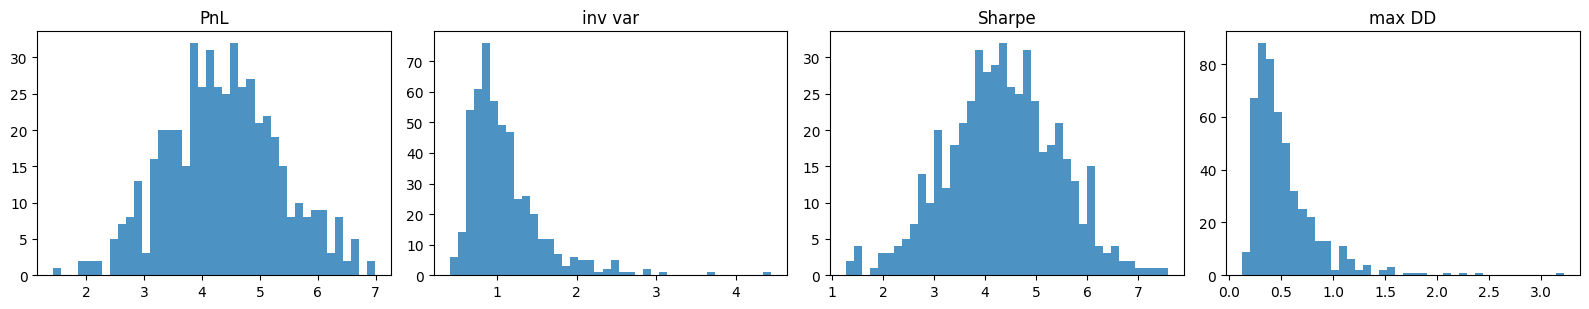

{
  "pnl": {
    "mean": 4.37196540463752,
    "std": 0.9721922932028442,
    "p5": 2.77224088893214,
    "p50": 4.350025857018409,
    "p95": 6.0945468973913295
  },
  "inv_var": {
    "mean": 1.0923676073744528,
    "std": 0.4669451099248079,
    "p5": 0.6187168406203113,
    "p50": 0.9796079939109877,
    "p95": 2.0103896651299666
  },
  "sharpe": {
    "mean": 4.348437150861799,
    "std": 1.0862339332002426,
    "p5": 2.6328146035009166,
    "p50": 4.342965878779437,
    "p95": 6.096577656996442
  },
  "max_drawdown": {
    "mean": 0.5274746567580201,
    "std": 0.3292405504513654,
    "p5": 0.22774312571182803,
    "p50": 0.4382415004305358,
    "p95": 1.1266900179469417
  }
}


In [7]:
res = run_hpc(thb, ths, cov_buy, cov_sell, params, n_sims=500, c=1.0, n_jobs=-1)
print('sims:', res.n_success, ' rejected draws:', res.n_rejected_draws)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, (arr, lab) in zip(axes, [(res.pnl,'PnL'),(res.inv_var,'inv var'),
                                  (res.sharpe,'Sharpe'),(res.max_drawdown,'max DD')]):
    ax.hist(arr[np.isfinite(arr)], bins=40, alpha=0.8); ax.set_title(lab)
plt.tight_layout(); plt.show()
import json; print(json.dumps(res.summary(), indent=2))

---
**Full study & report:** run `python -m analysis.robust_market_making` from the
project root. Figures land in `plots/robust_market_making/`, numeric artefacts in
`results/robust/`, and the conference-ready methodology in
`reports/robust_market_making.md`.